# 02 — Food-101 alt kümesi EDA (Adım 7)

25 sınıflık alt küme (`src/data.py` → `FOOD101_CLASSES`), `scripts/get_food101.py fetch` ile iner.
Baştan sona çalıştırıldığında tüm sayıları ve `results/figures/f101_*.png` figürlerini yeniden üretir
(Mac'te ~5 dk; gömme hesabı 25.000 görüntü).

**Kararlar ve bulguların özeti en altta (§7).**

In [1]:
import os, sys, json, hashlib, warnings
warnings.filterwarnings("ignore", message="IProgress not found")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, timm
from PIL import Image
from torch.utils.data import DataLoader, Dataset

from src.config import FOOD101_DIR, RESULTS_DIR, get_device
from src.data import FOOD101_CLASSES, FOOD101_EXCLUDE, Food101Subset
from src.plot_style import INK, SERIES, apply, savefig
from src.transforms import classification_transform

apply()
pd.set_option("display.width", 160)
BASE = FOOD101_DIR / "food-101"
# Analiz HAM bölmelerde (exclude=False); bulunan sorunlu görüntüler §6'da çıkarılır.
splits = {s: Food101Subset(s, transform=None, exclude=False) for s in ("train", "val", "test")}
df = pd.DataFrame([{"split": s, "path": p, "label": l, "cls": FOOD101_CLASSES[l], "id": f"{p.parent.name}/{p.stem}"}
                   for s, ds in splits.items() for p, l in ds.samples])

def show_images(paths, titles, ncols, name, w=2.0):
    nrows = (len(paths) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, w * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, p, t in zip(axes.flat, paths, titles):
        ax.imshow(Image.open(p))
        ax.set_title(t, fontsize=8, fontweight="normal", color=INK["secondary"])
    fig.tight_layout()
    savefig(fig, name, dpi=110)
    return fig

## 1. Alt küme: sayılar, boyutlar, kopyalar

In [2]:
counts = df.groupby(["cls", "split"]).size().unstack()[["train", "val", "test"]]
print("Sınıf başına görüntü (tüm sınıflarda aynı mı?):", {s: sorted(counts[s].unique()) for s in counts})
print("Toplam:", df.split.value_counts()[["train", "val", "test"]].to_dict())

orig = json.load(open(BASE / "meta" / "original_sizes.json"))
o = pd.DataFrame([{"id": k, "w": v[0], "h": v[1], "mode": v[2]} for k, v in orig.items()])
o["long"] = o[["w", "h"]].max(axis=1)
print(f"\nOrijinal görüntüler: uzun kenar = 512 px olanlar %{100 * (o.long == 512).mean():.1f}; "
      f"kısa kenar min {o[['w','h']].min(axis=1).min()} px")
print("Renk modları:", o["mode"].value_counts().to_dict(), "→ hepsi RGB'ye çevrildi")

df["md5"] = [hashlib.md5(open(p, "rb").read()).hexdigest() for p in df.path]
dup = df[df.md5.duplicated(keep=False)].sort_values("md5")
print(f"\nBirebir kopya görüntü: {dup.md5.nunique()} grup, {len(dup)} dosya")
if len(dup):
    display(dup[["md5", "split", "cls", "id"]])

Sınıf başına görüntü (tüm sınıflarda aynı mı?): {'train': [np.int64(675)], 'val': [np.int64(75)], 'test': [np.int64(250)]}
Toplam: {'train': 16875, 'val': 1875, 'test': 6250}

Orijinal görüntüler: uzun kenar = 512 px olanlar %100.0; kısa kenar min 140 px
Renk modları: {'RGB': 24998, 'L': 2} → hepsi RGB'ye çevrildi



Birebir kopya görüntü: 17 grup, 34 dosya


,md5,split,cls,id
23716,002afac8ab2f75e9b2f664c2add4daec,test,spaghetti_bolognese,spaghetti_bolognese/476276
23722,002afac8ab2f75e9b2f664c2add4daec,test,spaghetti_bolognese,spaghetti_bolognese/585440
1199,083f06103a10c072bf360a36442352e5,train,caesar_salad,caesar_salad/3627235
1200,083f06103a10c072bf360a36442352e5,train,caesar_salad,caesar_salad/3627251
10396,09aa49e280a447c0e196c0e683604ca2,train,pancakes,pancakes/2619752
9767,09aa49e280a447c0e196c0e683604ca2,train,omelette,omelette/2619753
6723,11697527c53ffa00c9b59748120645fd,train,greek_salad,greek_salad/857079
6726,11697527c53ffa00c9b59748120645fd,train,greek_salad,greek_salad/862426
13604,1e3d2e2b4975ffb22500f514162dcbf9,train,spaghetti_carbonara,spaghetti_carbonara/1551970
23780,1e3d2e2b4975ffb22500f514162dcbf9,test,spaghetti_carbonara,spaghetti_carbonara/1552336


## 2. Sınıflar

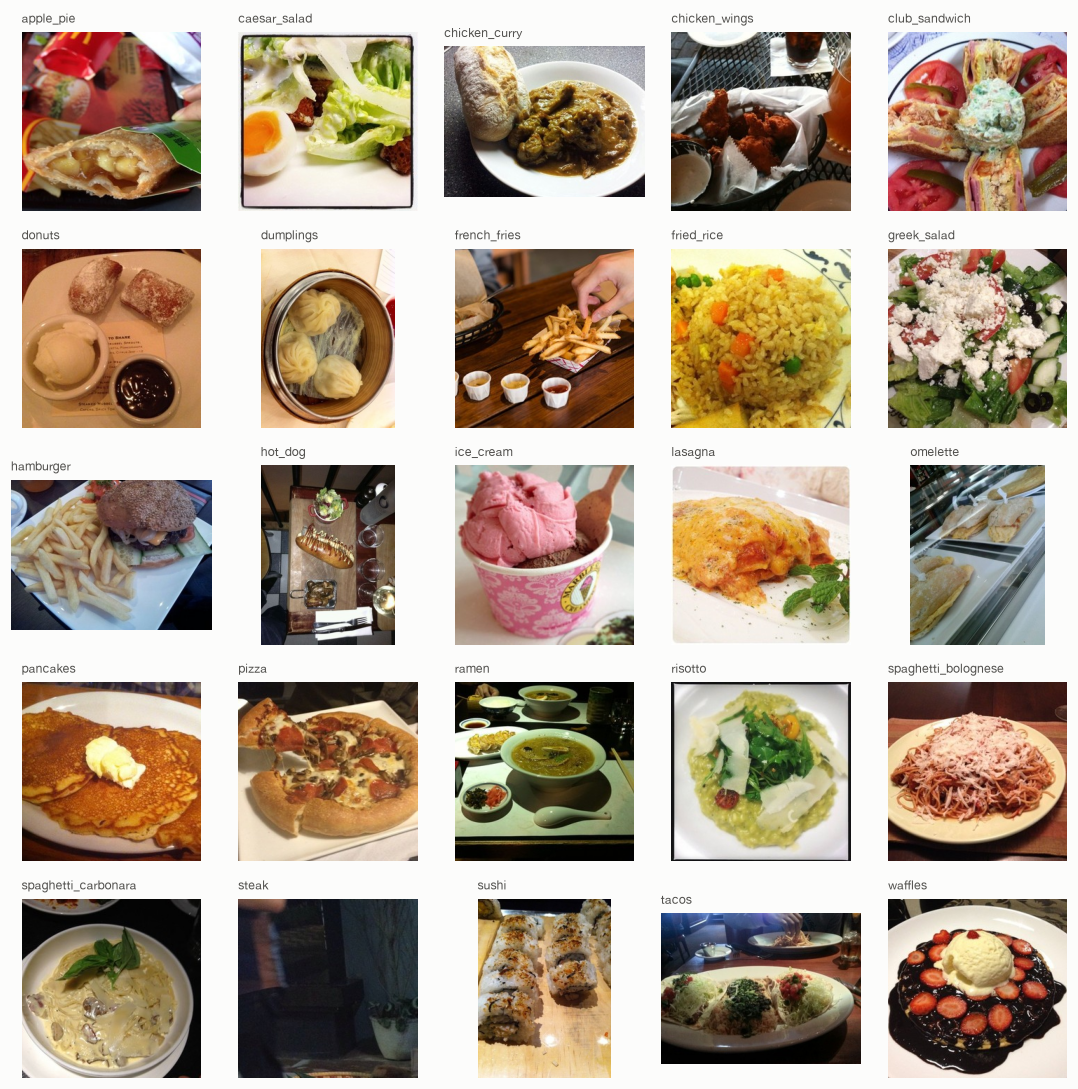

In [3]:
pick = [df[(df.split == "train") & (df.label == l)].sample(1, random_state=42).path.iloc[0] for l in range(25)]
fig = show_images(pick, FOOD101_CLASSES, ncols=5, name="f101_siniflar")

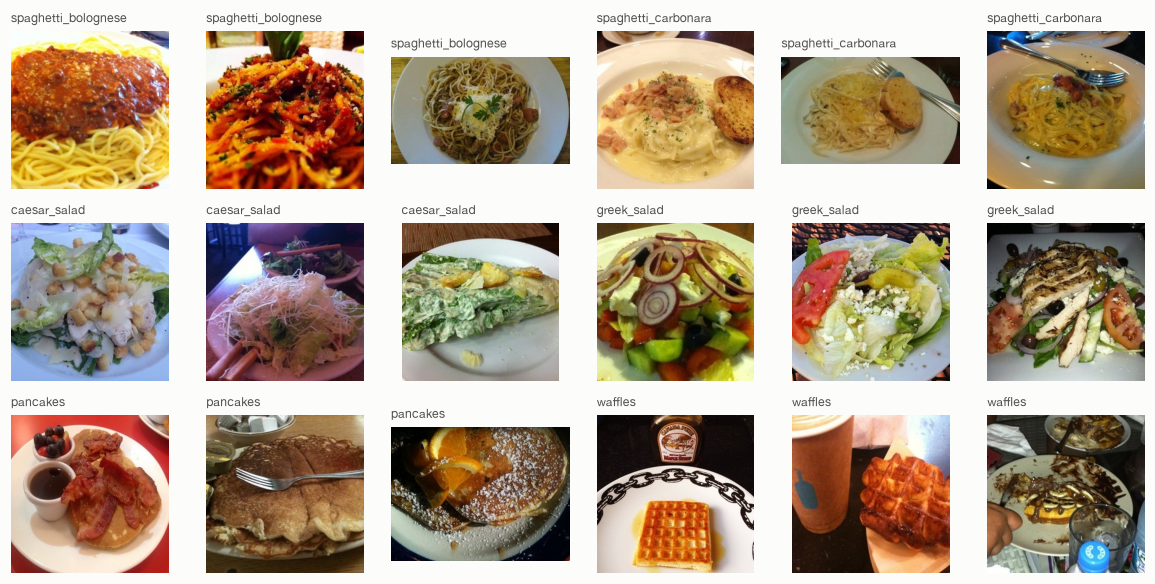

In [4]:
pairs = [("spaghetti_bolognese", "spaghetti_carbonara"), ("caesar_salad", "greek_salad"), ("pancakes", "waffles")]
paths, titles = [], []
for a, b in pairs:
    for c in (a, b):
        s = df[(df.split == "test") & (df.cls == c)].sample(3, random_state=1)
        paths += list(s.path); titles += [c] * 3
fig = show_images(paths, titles, ncols=6, name="f101_karisabilir_ciftler", w=1.8)

## 3. Görüntü gömmeleri
ImageNet ResNet-50 (önceden eğitilmiş, ince ayarsız) ile her görüntünün 2048 boyutlu gömmesi. §4 ve §5 bunları kullanır.

In [5]:
class Paths(Dataset):
    def __init__(self, paths): self.paths, self.t = list(paths), classification_transform(train=False)
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return self.t(Image.open(self.paths[i]).convert("RGB"))

dev = get_device()
m = timm.create_model("resnet50", pretrained=True).to(dev).eval()
with torch.no_grad():
    F = torch.cat([torch.nn.functional.normalize(m.forward_head(m.forward_features(x.to(dev)), pre_logits=True), dim=1).cpu()
                   for x in DataLoader(Paths(df.path), batch_size=128, num_workers=0)])
print("Gömme:", tuple(F.shape))

Gömme: (25000, 2048)


## 4. Etiket gürültüsü
Food-101'in yazarları train görüntülerini **bilerek temizlememiş**; test görüntüleri elle temizlenmiş. Bunu ölçmek için her görüntünün
train içindeki **10 en yakın komşusuna** bakıyoruz: komşuların **hiçbiri** aynı etiketi taşımıyorsa görüntü "şüpheli".
Test kümesi kontrol grubu: temiz bir kümede şüpheli oranı daha düşük olmalı.

In [6]:
is_train = torch.tensor((df.split == "train").values)
Ftr, ytr = F[is_train], torch.tensor(df.label.values)[is_train]
idx_tr = torch.where(is_train)[0]

def neighbor_labels(Fq, exclude_self_idx=None, k=10, chunk=2048):
    out = []
    for i in range(0, len(Fq), chunk):
        s = Fq[i:i + chunk] @ Ftr.T
        if exclude_self_idx is not None:
            rows = torch.arange(len(s))
            s[rows, exclude_self_idx[i:i + chunk]] = -1
        out.append(ytr[s.topk(k, dim=1).indices])
    return torch.cat(out)

pos_in_train = torch.full((len(df),), -1, dtype=torch.long); pos_in_train[idx_tr] = torch.arange(len(idx_tr))
res = {}
for split in ("train", "test"):
    sel = torch.tensor((df.split == split).values)
    nl = neighbor_labels(F[sel], pos_in_train[sel] if split == "train" else None)
    agree = (nl == torch.tensor(df.label.values)[sel][:, None]).sum(1)
    df.loc[sel.numpy(), "nn_agree"] = agree.numpy()
    df.loc[sel.numpy(), "nn_major"] = nl.mode(1).values.numpy()
    res[split] = (agree == 0).float().mean().item()
    print(f"{split:<5}: 10 komşunun hiçbiri aynı etikette değil → %{100 * res[split]:.1f}")

train: 10 komşunun hiçbiri aynı etikette değil → %8.0


test : 10 komşunun hiçbiri aynı etikette değil → %5.5


Şüpheli train görüntüsü: 1353 / 16875
En çok şüpheli içeren sınıflar:


cls
apple_pie        97
chicken_curry    82
tacos            77
omelette         76
dumplings        70
hot_dog          70
Name: count, dtype: int64

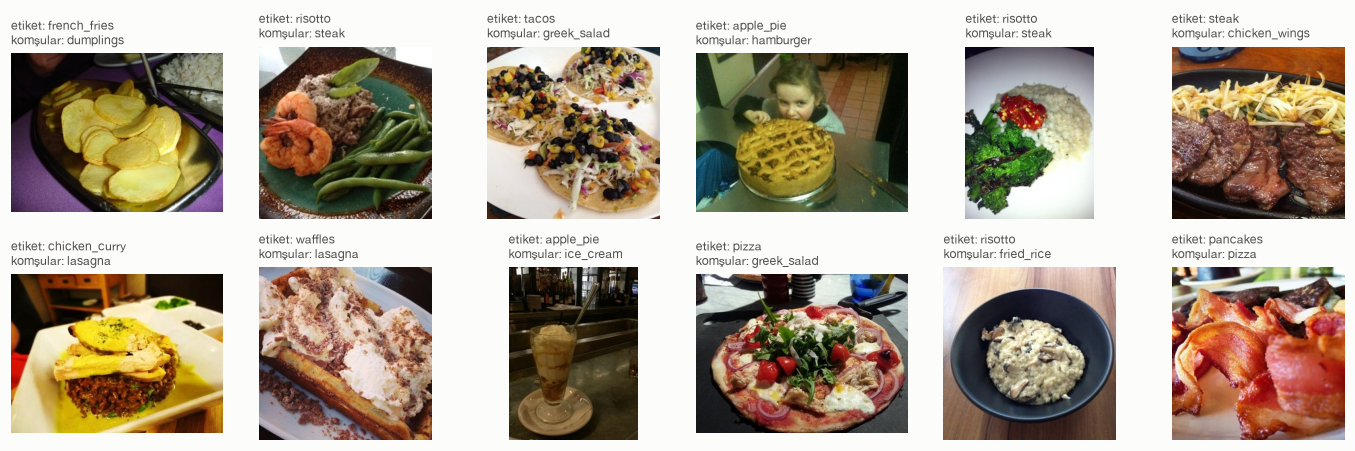

In [7]:
sus = df[(df.split == "train") & (df.nn_agree == 0)].copy()
print(f"Şüpheli train görüntüsü: {len(sus)} / {(df.split == 'train').sum()}")
print("En çok şüpheli içeren sınıflar:"); display(sus.cls.value_counts().head(6))
ex = sus.sample(min(12, len(sus)), random_state=0)
fig = show_images(ex.path, [f"etiket: {c}\nkomşular: {FOOD101_CLASSES[int(mj)]}" for c, mj in zip(ex.cls, ex.nn_major)],
                  ncols=6, name="f101_supheli_etiketler", w=2.1)

## 5. Train/val–test yakın kopyaları
Her test görüntüsünün en benzer train/val görüntüsü. Kosinüs benzerliği ≥ 0,98 olanlar aynı fotoğraf (birebir ya da farklı kırpılmış) → sızıntı.

en yakın train benzerliği ≥ 0.9: 379 test görüntüsü
en yakın train benzerliği ≥ 0.95: 68 test görüntüsü
en yakın train benzerliği ≥ 0.98: 9 test görüntüsü

Benzerlik ≥ 0,98 olan çiftler:
  0.995  test:hot_dog/413426  ↔  train:hot_dog/410713  (FOOD101_EXCLUDE ✓)
  1.000  test:lasagna/499765  ↔  train:lasagna/499859  (FOOD101_EXCLUDE ✓)
  0.986  test:omelette/1600856  ↔  train:omelette/1748616  (FOOD101_EXCLUDE ✓)
  1.000  test:pancakes/92527  ↔  train:pancakes/85516  (FOOD101_EXCLUDE ✓)
  1.000  test:spaghetti_carbonara/1349091  ↔  train:spaghetti_carbonara/1348593  (FOOD101_EXCLUDE ✓)
  1.000  test:spaghetti_carbonara/1552336  ↔  train:spaghetti_carbonara/1551970  (FOOD101_EXCLUDE ✓)
  0.996  test:spaghetti_carbonara/3298793  ↔  train:spaghetti_carbonara/3302076  (FOOD101_EXCLUDE ✓)
  1.000  test:spaghetti_carbonara/501277  ↔  val:spaghetti_carbonara/501296  (FOOD101_EXCLUDE ✓)
  1.000  test:waffles/899285  ↔  train:waffles/961486  (FOOD101_EXCLUDE ✓)


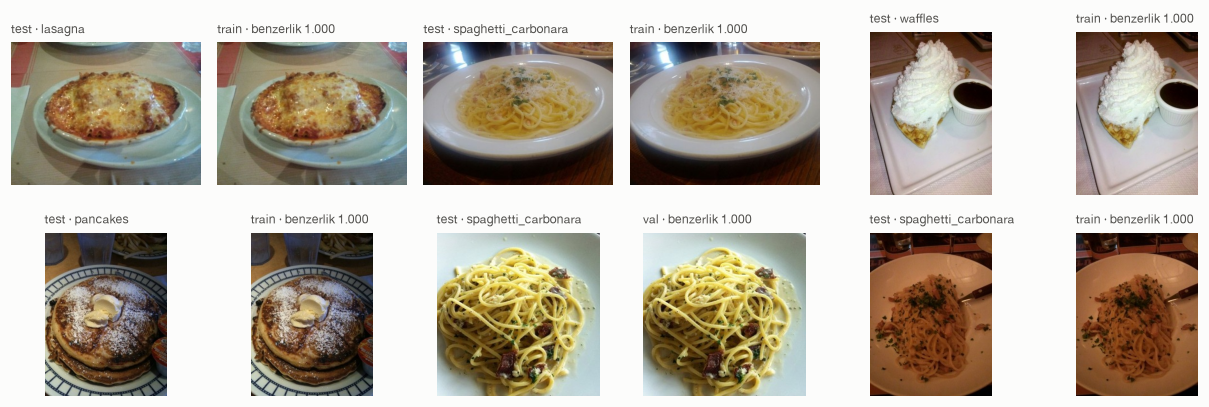

In [8]:
is_test = torch.tensor((df.split == "test").values)
Ftv = F[~is_test]
best_sim, best_idx = [], []
for i in range(0, int(is_test.sum()), 2048):
    s = F[is_test][i:i + 2048] @ Ftv.T
    v, j = s.max(1); best_sim.append(v); best_idx.append(j)
best_sim, best_idx = torch.cat(best_sim), torch.cat(best_idx)
for t in (0.90, 0.95, 0.98):
    print(f"en yakın train benzerliği ≥ {t}: {(best_sim >= t).sum().item()} test görüntüsü")
order = best_sim.argsort(descending=True)[:6]
te_df, tv_df = df[is_test.numpy()].reset_index(drop=True), df[~is_test.numpy()].reset_index(drop=True)
print("\nBenzerlik ≥ 0,98 olan çiftler:")
for o in (best_sim >= 0.98).nonzero().flatten().tolist():
    m_ = tv_df.iloc[best_idx[o].item()]
    print(f"  {best_sim[o]:.3f}  test:{te_df.id[o]}  ↔  {m_.split}:{m_.id}  {'(FOOD101_EXCLUDE ✓)' if m_.id in FOOD101_EXCLUDE else '(EKSİK!)'}")
paths, titles = [], []
for o in order.tolist():
    m_ = tv_df.iloc[best_idx[o].item()]
    paths += [te_df.path[o], m_.path]
    titles += [f"test · {te_df.cls[o]}", f"{m_.split} · benzerlik {best_sim[o]:.3f}"]
fig = show_images(paths, titles, ncols=6, name="f101_yakin_kopyalar", w=1.9)

## 6. Çıkarılan görüntüler ve veri kartı
`FOOD101_EXCLUDE` (src/data.py): test kopyalarının train/val tarafı + çelişkili etiketli çift. Test kümesine dokunulmaz.

In [9]:
for k, v in FOOD101_EXCLUDE.items():
    print(f"  {k:<30} {v}")
final = {s: len(Food101Subset(s, transform=None)) for s in ("train", "val", "test")}
print("\nSon sayılar (exclude=True):", final)
card = pd.DataFrame({s: {"görüntü": final[s], "sınıf başına": "675 (−çıkarılanlar)" if s == "train" else ("75 (−çıkarılanlar)" if s == "val" else "250"),
                         "kaynak": "resmi train (temizlenmemiş)" if s != "test" else "resmi test (elle temizlenmiş)"}
                     for s in ("train", "val", "test")})
card.to_csv(RESULTS_DIR / "data_card_food101.csv")
card

  hot_dog/410713                 test hot_dog/413426 ile neredeyse aynı (0,995)
  lasagna/499859                 test lasagna/499765 ile birebir aynı
  omelette/1748616               test omelette/1600856 ile neredeyse aynı (0,986)
  pancakes/85516                 test pancakes/92527 ile birebir aynı
  spaghetti_carbonara/1348593    test spaghetti_carbonara/1349091 ile birebir aynı
  spaghetti_carbonara/1551970    test spaghetti_carbonara/1552336 ile birebir aynı
  spaghetti_carbonara/3302076    test spaghetti_carbonara/3298793 ile neredeyse aynı (0,996)
  spaghetti_carbonara/501296     test spaghetti_carbonara/501277 ile birebir aynı (val'de)
  waffles/961486                 test waffles/899285 ile birebir aynı
  omelette/2619753               pancakes/2619752 ile aynı dosya
  pancakes/2619752               omelette/2619753 ile aynı dosya

Son sayılar (exclude=True): {'train': 16865, 'val': 1874, 'test': 6250}


,train,val,test
görüntü,16865,1874,6250
sınıf başına,675 (−çıkarılanlar),75 (−çıkarılanlar),250
kaynak,resmi train (temizlenmemiş),resmi train (temizlenmemiş),resmi test (elle temizlenmiş)


## 7. Özet: bulgular ve kararlar

| # | Bulgu | Karar / etki |
| --- | --- | --- |
| 1 | Sınıflar dengeli: sınıf başına 675 train / 75 val / 250 test. Orijinallerin uzun kenarı 512 px; 2 görüntü gri tonlu | Alt kümede kısa kenar 256 px'e küçültüldü, hepsi RGB'ye çevrildi |
| 2 | **9 test görüntüsünün train/val'de birebir ya da neredeyse aynı kopyası var** (6 birebir, 3 farklı kırpım) | Train/val kopyaları `FOOD101_EXCLUDE` ile çıkarıldı; test'e dokunulmadı |
| 3 | Aynı fotoğraf hem `omelette` hem `pancakes` etiketli | İkisi de çıkarıldı |
| 4 | Train'de etiket gürültüsü var: 10 komşusunun hiçbiri aynı etikette olmayan görüntü train'de %8,0, elle temizlenmiş test'te %5,5. Gözle bakılan 12 şüpheli örneğin yaklaşık yarısı gerçekten yanlış etiketli | Hangisinin yanlış olduğu kesin değil → **çıkarılmıyor**. Plandaki label smoothing (0,1) gürültüye karşı koruma sağlar |
| 5 | Karışabilir çiftler (bolognese/carbonara, caesar/greek, pancakes/waffles) görsel olarak gerçekten benzer | Karışıklık matrisinde bu çiftlere bakılacak (Adım 15–16) |

**Son sayılar:** 16.865 train / 1.874 val / 6.250 test. Figürler: `results/figures/f101_*.png` · Veri kartı: `results/data_card_food101.csv`